In [16]:
import numpy as np
import matplotlib.pyplot as plt

import bachelier_pricer
import importlib

importlib.reload(bachelier_pricer)
from bachelier_pricer import *

In [17]:
(F0, X, r, sigma, T) = (10, 10, 0.05, 0.2, 9/12)

payment_times = np.array([
    T + 0.2,
    T + 0.7,
    T + 1.1,
    T + 2.5,
    T + 3.6
])

option_type = "call"
swaption_type = "payer"

S0 = 11

n_time = 800
n_sim_option = 10_000
n_sim_swaption = 30_000
seed = 0

Nt = 250
NF = 200
NS = 200

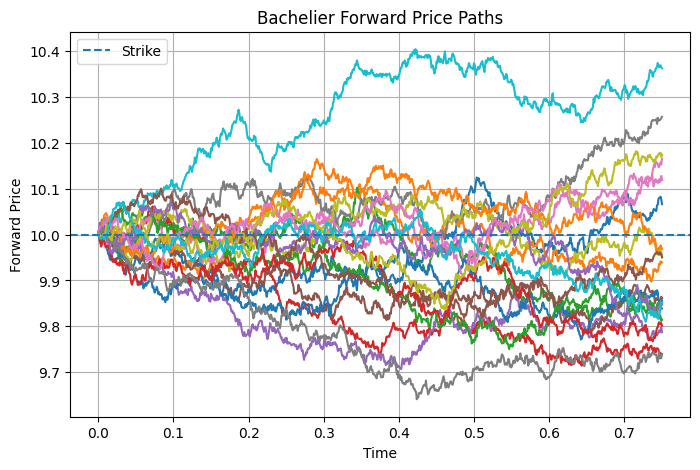

In [18]:
F_paths = bachelier_paths(
    F0=F0,
    sigma=sigma,
    T=T,
    n_time=n_time,
    n_sim=20,
    seed=seed
)

time_grid = np.linspace(0, T, n_time + 1)

plt.figure(figsize=(8, 5))

for i in range(F_paths.shape[0]):
    plt.plot(time_grid, F_paths[i])

plt.axhline(X, linestyle="--", label="Strike")

plt.xlabel("Time")
plt.ylabel("Forward Price")
plt.title("Bachelier Forward Price Paths")
plt.legend()
plt.grid()

plt.show()

In [19]:

price_analytical = bachelier_option_price_analytical(
    F0=F0,
    X=X,
    r=r,
    sigma=sigma,
    T=T,
    option_type=option_type
)

price_mc = bachelier_option_price_mc(
    F0=F0,
    X=X,
    r=r,
    sigma=sigma,
    T=T,
    n_time=n_time,
    n_sim=n_sim_option,
    option_type=option_type,
    seed=seed
)

price_cn = bachelier_option_price_cn(
    F0=F0,
    X=X,
    r=r,
    sigma=sigma,
    T=T,
    Nt=Nt,
    NF=NF,
    option_type=option_type
)

print(f"Analytical Price      : {price_analytical:.6f}")
print(f"Monte Carlo Price     : {price_mc:.6f}")
print(f"Crank-Nicolson Price  : {price_cn:.6f}")

Analytical Price      : 0.066556
Monte Carlo Price     : 0.068121
Crank-Nicolson Price  : 0.066586


In [20]:
price_swaption_analytical = bachelier_swaption_price_analytical(
    S0=S0,
    X=X,
    r=r,
    sigma=sigma,
    T=T,
    payment_times=payment_times,
    swaption_type=swaption_type
)

price_swaption_mc = bachelier_swaption_price_mc(
    S0=S0,
    X=X,
    r=r,
    sigma=sigma,
    T=T,
    payment_times=payment_times,
    n_time=n_time,
    n_sim=n_sim_swaption,
    swaption_type=swaption_type,
    seed=seed
)

price_swaption_cn = bachelier_swaption_price_cn(
    S0=S0,
    X=X,
    r=r,
    sigma=sigma,
    T=T,
    payment_times=payment_times,
    Nt=Nt,
    NS=NS,
    swaption_type=swaption_type
)

print(f"Analytical Swaption Price      : {price_swaption_analytical:.6f}")
print(f"Monte Carlo Swaption Price     : {price_swaption_mc:.6f}")
print(f"Crank-Nicolson Swaption Price  : {price_swaption_cn:.6f}")

Analytical Swaption Price      : 3.095418
Monte Carlo Swaption Price     : 3.096987
Crank-Nicolson Swaption Price  : 3.095418


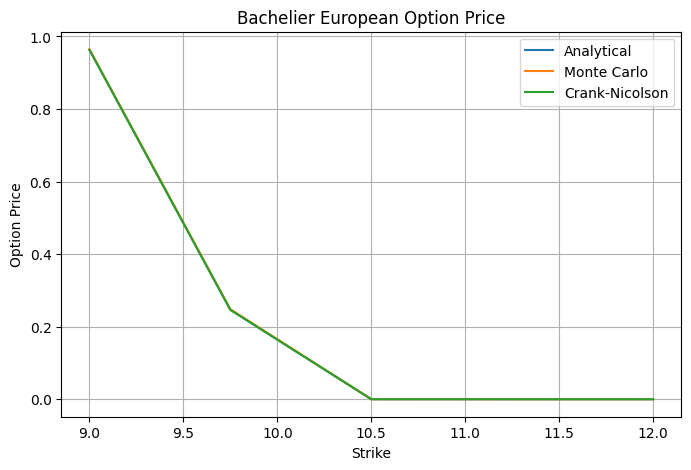

In [21]:
X_grid = np.linspace(9.0, 12.0, 5)

price_analytical = []
price_mc = []
price_cn = []

for X_i in X_grid:

    price_analytical.append(
        bachelier_option_price_analytical(
            F0, X_i, r, sigma, T,
            option_type=option_type
        )
    )

    price_mc.append(
        bachelier_option_price_mc(
            F0, X_i, r, sigma, T,
            n_time=n_time,
            n_sim=n_sim_option,
            option_type=option_type,
            seed=seed
        )
    )

    price_cn.append(
        bachelier_option_price_cn(
            F0, X_i, r, sigma, T,
            Nt=Nt,
            NF=NF,
            option_type=option_type
        )
    )

plt.figure(figsize=(8, 5))

plt.plot(
    X_grid, price_analytical,
    label="Analytical"
)

plt.plot(
    X_grid, price_mc,
    label="Monte Carlo"
)

plt.plot(
    X_grid, price_cn,
    label="Crank-Nicolson"
)

plt.xlabel("Strike")
plt.ylabel("Option Price")
plt.title("Bachelier European Option Price")
plt.legend()
plt.grid()

plt.show()

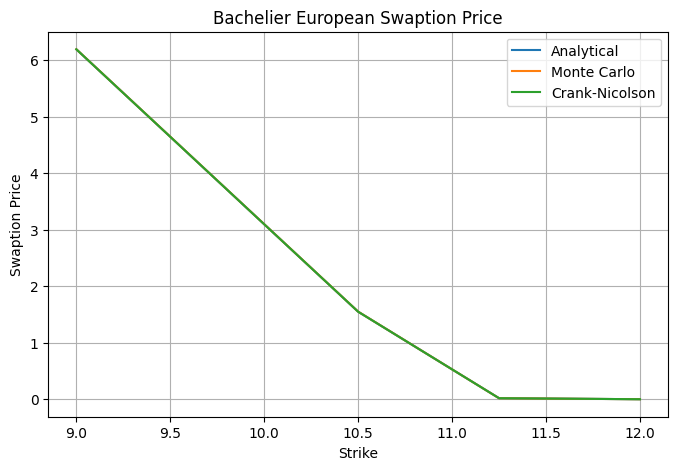

In [22]:
X_grid = np.linspace(9.0, 12.0, 5)

price_analytical = []
price_mc = []
price_cn = []

for X_i in X_grid:

    price_analytical.append(
        bachelier_swaption_price_analytical(
            S0, X_i, r, sigma, T,
            payment_times,
            swaption_type=swaption_type
        )
    )

    price_mc.append(
        bachelier_swaption_price_mc(
            S0, X_i, r, sigma, T,
            payment_times,
            n_time=n_time,
            n_sim=n_sim_swaption,
            swaption_type=swaption_type,
            seed=seed
        )
    )

    price_cn.append(
        bachelier_swaption_price_cn(
            S0, X_i, r, sigma, T,
            payment_times,
            Nt=Nt,
            NS=NS,
            swaption_type=swaption_type
        )
    )

plt.figure(figsize=(8, 5))

plt.plot(
    X_grid, price_analytical,
    label="Analytical"
)

plt.plot(
    X_grid, price_mc,
    label="Monte Carlo"
)

plt.plot(
    X_grid, price_cn,
    label="Crank-Nicolson"
)

plt.xlabel("Strike")
plt.ylabel("Swaption Price")
plt.title("Bachelier European Swaption Price")
plt.legend()
plt.grid()

plt.show()